# PicoHarp Pump-Probe Folding

Fold PicoHarp T2 photon timestamps onto the effective pump-probe period. The raw cycle contains two identical pulses, so the analysis period is `cycle_period / 2`. The first 100 us are kept in the plots so the pump-transmission artifact stays visible.

In [1]:
import json
import subprocess
import sys
import threading
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import Pyro4

Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"
Pyro4.config.THREADPOOL_SIZE = 20
Pyro4.config.THREADPOOL_SIZE_MIN = 4

SERVER_URI = "PYRO:PumpProbeAnalysis@127.0.0.1:9113"
SERVER_SCRIPT = Path.cwd() / "PicoHarp_analysis_PP_srv.py"
server_process = None

try:
    stop_logs.set()
except NameError:
    pass

def start_local_server_if_needed(uri=SERVER_URI):
    global server_process
    try:
        probe = Pyro4.Proxy(uri)
        probe.ping()
        return
    except Exception:
        pass

    if server_process is not None and server_process.poll() is None:
        return

    server_process = subprocess.Popen(
        [sys.executable, "-u", str(SERVER_SCRIPT)],
        cwd=str(SERVER_SCRIPT.parent),
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
    )
    deadline = time.time() + 10.0
    last_error = None
    while time.time() < deadline:
        try:
            probe = Pyro4.Proxy(uri)
            probe.ping()
            print(f"Started local pump-probe server from {SERVER_SCRIPT}")
            return
        except Exception as exc:
            last_error = exc
            time.sleep(0.2)
    raise RuntimeError(f"Could not start pump-probe server at {uri}: {last_error}")


def analysis_setup(uri=SERVER_URI):
    global analysis_cmd, stop_logs
    start_local_server_if_needed(uri)
    analysis_cmd = Pyro4.Proxy(uri)
    stop_logs = threading.Event()

    def log_poller():
        analysis_log = Pyro4.Proxy(uri)
        idx = 0
        progress_active = False
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        sys.stdout.write("\r\033[K")
                        sys.stdout.write(line[1:])
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write("\n")
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as exc:
                if progress_active:
                    sys.stdout.write("\n")
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {exc}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)

    threading.Thread(target=log_poller, daemon=True).start()
    print("------------------ LOG ------------------", flush=True)
    analysis_cmd.ping()
    return analysis_cmd




In [2]:
analysis_cmd = analysis_setup()


------------------ LOG ------------------


# Sync-clock pump-probe analysis 
CH1 resets the clock; CH0 photons are folded relative to the most recent CH1 tick.

In [3]:
# Compact overlay helper for CH1-sync-folded pump-probe traces
import json
from pathlib import Path

DATA_ROOT = ""
def _as_acq_paths(filenames, data_root=DATA_ROOT):
    paths = []
    data_root = Path(data_root)
    for item in filenames:
        if isinstance(item, (int, np.integer)):
            paths.append(data_root / f"acq_{int(item)}.b")
        else:
            path = Path(item)
            if not path.is_absolute():
                path = data_root / path
            paths.append(path)
    return paths


def _metadata_path_for_b_file(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_metadata.json")


def _metadata_value(filepath, key):
    metadata_path = _metadata_path_for_b_file(filepath)
    with metadata_path.open("r", encoding="utf-8") as f:
        payload = json.load(f)

    value = payload
    for part in key.split("."):
        value = value[part]
    return value


def _sorted_by_metadata(filenames, *, key="metadata.B_field", data_root=DATA_ROOT):
    rows = []
    for path in _as_acq_paths(filenames, data_root=data_root):
        rows.append((float(_metadata_value(path, key)), path))
    rows.sort(key=lambda row: row[0])
    return rows


def _folded_folder_for_b_file(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_pump_probe_folded")


def _plot_file_token(paths):
    paths = [Path(path) for path in paths]
    if len(paths) == 1:
        return paths[0].stem
    return f"{paths[0].stem}_to_{paths[-1].stem}_{len(paths)}files"


def _save_plot_figure(fig, paths, plot_kind, *, fig_name=None, dpi=200):
    if not paths:
        return None
    paths = [Path(path) for path in paths]
    if len(paths) == 1:
        out_dir = _folded_folder_for_b_file(paths[0])
    else:
        out_dir = paths[0].parent
    out_dir.mkdir(parents=True, exist_ok=True)
    if fig_name is None:
        fig_name = f"{_plot_file_token(paths)}_{plot_kind}.png"
    fig_path = Path(fig_name)
    if fig_path.suffix == "":
        fig_path = fig_path.with_suffix(".png")
    if not fig_path.is_absolute():
        fig_path = out_dir / fig_path.name
    fig.savefig(fig_path, dpi=dpi, bbox_inches="tight")
    return fig_path


def _time_unit_scale_from_us(unit):
    unit = str(unit).lower()
    if unit == "us":
        return 1.0
    if unit == "ms":
        return 1e-3
    raise ValueError("unit must be 'us' or 'ms'.")


def _time_from_us(time_us, unit):
    return np.asarray(time_us, dtype=float) * _time_unit_scale_from_us(unit)


def _window_to_us(window, unit="us"):
    if window is None:
        return None
    window_us = np.asarray(window, dtype=float)
    if window_us.shape != (2,):
        raise ValueError("Windows must be two values: [start, stop].")
    if str(unit).lower() == "ms":
        window_us = window_us * 1e3
    elif str(unit).lower() != "us":
        raise ValueError("unit must be 'us' or 'ms'.")
    return window_us


def _normalize_measurement_ranges(ranges):
    if ranges is None:
        return None
    arr = np.asarray(ranges, dtype=float)
    if arr.size == 0:
        return None
    arr = arr.reshape(-1, 2)
    if np.any(arr[:, 1] <= arr[:, 0]):
        raise ValueError("Measurement ranges must be [start, stop] in seconds with stop > start.")
    return arr


def _ranges_match(cached, requested):
    requested = _normalize_measurement_ranges(requested)
    if cached is None:
        cached = None
    else:
        cached_arr = np.asarray(cached, dtype=float)
        cached = cached_arr.reshape(-1, 2) if cached_arr.size else None
    if requested is None:
        return cached is None
    if cached is None or cached.shape != requested.shape:
        return False
    return np.allclose(cached, requested, rtol=0, atol=1e-12)


def _bins_overlapping_window(time_centers_us, window_us):
    time_centers_us = np.asarray(time_centers_us, dtype=float)
    window_us = np.asarray(window_us, dtype=float)
    if time_centers_us.size == 0:
        return np.zeros(0, dtype=bool)
    if time_centers_us.size == 1:
        return np.ones(1, dtype=bool)

    boundaries = 0.5 * (time_centers_us[:-1] + time_centers_us[1:])
    left = np.empty_like(time_centers_us)
    right = np.empty_like(time_centers_us)
    left[1:] = boundaries
    right[:-1] = boundaries
    left[0] = time_centers_us[0] - 0.5 * (time_centers_us[1] - time_centers_us[0])
    right[-1] = time_centers_us[-1] + 0.5 * (time_centers_us[-1] - time_centers_us[-2])
    return (right >= window_us[0]) & (left <= window_us[1])


def _rebin_trace(time_us, rate_kcps, counts, bin_us=None):
    if bin_us is None:
        return time_us, rate_kcps, counts
    bin_us = float(bin_us)
    if bin_us <= 0:
        raise ValueError("bin_us must be positive.")

    native_bin_us = float(np.median(np.diff(time_us)))
    if bin_us < native_bin_us * 0.999:
        raise ValueError(
            f"bin_us={bin_us:g} us is finer than the native folded bin width "
            f"of {native_bin_us:g} us. Re-run the server fold with finer native bins "
            "if you need sub-us resolution."
        )

    rebin_factor = max(1, int(round(bin_us / native_bin_us)))
    actual_bin_us = rebin_factor * native_bin_us
    if not np.isclose(actual_bin_us, bin_us, rtol=0.20, atol=1e-9):
        raise ValueError(
            f"bin_us={bin_us:g} us is not within 20% of an integer multiple of the native "
            f"{native_bin_us:g} us bins. Use about {actual_bin_us:g} us or another multiple."
        )
    if rebin_factor == 1:
        return time_us, rate_kcps, counts

    n = (len(time_us) // rebin_factor) * rebin_factor
    if n == 0:
        raise ValueError(f"bin_us={bin_us:g} us is too coarse for this trace.")

    time_rebinned = time_us[:n].reshape(-1, rebin_factor).mean(axis=1)
    rate_rebinned = rate_kcps[:n].reshape(-1, rebin_factor).mean(axis=1)
    counts_rebinned = counts[:n].reshape(-1, rebin_factor).sum(axis=1)
    return time_rebinned, rate_rebinned, counts_rebinned


def _sync_signal_part(signal_channels):
    return "ch" + "-".join(str(int(ch)) for ch in signal_channels)


def _sync_fold_folder(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_pump_probe_folded")


def _cached_sync_fold_path(filepath, *, sync_channel, signal_channels, requested_bin_us, sync_tick_stride=1,
                           measurement_include_ranges_s=None, measurement_exclude_ranges_s=None,
                           measurement_filter_label=None):
    folder = _sync_fold_folder(filepath)
    if not folder.exists():
        return None

    base = Path(filepath).stem
    signal_part = _sync_signal_part(signal_channels)
    pattern = f"{base}_syncfold_syncch{int(sync_channel)}_{signal_part}_ch1bounded*_bin*us.npz"
    prefer_excluded_cache = measurement_include_ranges_s is None and measurement_exclude_ranges_s is None
    candidates = []
    for path in folder.glob(pattern):
        try:
            with np.load(path, allow_pickle=False) as z:
                native_bin_us = float(z["phase_bin_us"])
                cached_stride = int(z["sync_tick_stride"]) if "sync_tick_stride" in z.files else 1
                cached_include = z["measurement_include_ranges_s"] if "measurement_include_ranges_s" in z.files else None
                cached_exclude = z["measurement_exclude_ranges_s"] if "measurement_exclude_ranges_s" in z.files else None
                cached_label = str(z["measurement_filter_label"]) if "measurement_filter_label" in z.files else None
                if "_include" not in path.name and "_exclude" not in path.name and cached_label is None:
                    cached_include = None
                    cached_exclude = None
        except Exception:
            continue

        factor = requested_bin_us / native_bin_us
        if cached_stride != int(sync_tick_stride):
            continue
        if factor < 0.999 or not np.isclose(factor, round(factor), rtol=0.20, atol=1e-9):
            continue

        if measurement_filter_label is not None and cached_label != str(measurement_filter_label):
            continue

        if prefer_excluded_cache:
            has_exclude_token = "_exclude" in path.name
            has_cached_exclude = cached_exclude is not None and np.asarray(cached_exclude).size > 0
            has_cached_include = cached_include is not None and np.asarray(cached_include).size > 0
            if has_cached_exclude and not has_cached_include:
                candidates.append((0, native_bin_us, path))
            elif not has_exclude_token and "_include" not in path.name:
                candidates.append((1, native_bin_us, path))
        elif _ranges_match(cached_include, measurement_include_ranges_s) and _ranges_match(cached_exclude, measurement_exclude_ranges_s):
            candidates.append((0, native_bin_us, path))

    if not candidates:
        return None
    return min(candidates, key=lambda item: (item[0], item[1]))[2]

def _circular_moving_average(values, window):
    values = np.asarray(values, dtype=float)
    window = int(max(1, window))
    if window <= 1 or values.size == 0:
        return values.copy()
    if window % 2 == 0:
        window += 1
    half = window // 2
    smoothed = np.zeros_like(values, dtype=float)
    for shift in range(-half, half + 1):
        smoothed += np.roll(values, shift)
    return smoothed / window


def _last_low_t0_us(phase_centers_us, phase_counts, *, threshold_fraction=0.05, smooth_fraction=0.002):
    phase_centers_us = np.asarray(phase_centers_us, dtype=float)
    counts = np.asarray(phase_counts, dtype=float)
    finite = np.isfinite(phase_centers_us) & np.isfinite(counts)
    if np.count_nonzero(finite) < 3:
        idx = int(np.nanargmin(counts))
        return float(phase_centers_us[idx]), float(counts[idx]), idx

    filled = counts.copy()
    fill_value = float(np.nanmedian(filled[finite]))
    filled[~np.isfinite(filled)] = fill_value
    smooth_window = max(1, min(51, int(round(filled.size * smooth_fraction))))
    smoothed = _circular_moving_average(filled, smooth_window)

    mean_counts = float(np.nanmean(smoothed[finite]))
    threshold = threshold_fraction * mean_counts
    low_mask = smoothed <= threshold
    if not np.any(low_mask):
        idx = int(np.nanargmin(smoothed))
        return float(phase_centers_us[idx]), float(smoothed[idx]), idx

    high_mask = ~low_mask
    high_run = max(2, min(10, smoothed.size // 100))
    for start in range(smoothed.size):
        run_idx = (start + np.arange(high_run)) % smoothed.size
        if np.all(high_mask[run_idx]):
            idx = (start - 1) % smoothed.size
            search_count = 0
            while not low_mask[idx] and search_count < smoothed.size:
                idx = (idx - 1) % smoothed.size
                search_count += 1
            return float(phase_centers_us[idx]), float(smoothed[idx]), int(idx)

    low_indices = np.flatnonzero(low_mask)
    idx = int(low_indices[-1])
    return float(phase_centers_us[idx]), float(smoothed[idx]), idx


def _t0_method_label(t0_method):
    if t0_method == "argmin":
        return "count minimum"
    if t0_method == "argmax":
        return "count maximum"
    if t0_method in {"last_low", "low_threshold", "threshold"}:
        return "last low-count bin"
    return str(t0_method)

def load_shifted_sync_trace(filepath, *, sync_channel=1, signal_channels=(0,), bin_us=1.0, sync_tick_stride=1,
                            measurement_include_ranges_s=None, measurement_exclude_ranges_s=None,
                            measurement_filter_label=None,
                            force_recompute=False, show_progress=False, t0_method="argmin"):
    filepath = Path(filepath)
    requested_bin_us = float(bin_us)
    signal_channels = tuple(int(ch) for ch in signal_channels)
    cached_path = None if force_recompute else _cached_sync_fold_path(
        filepath,
        sync_channel=sync_channel,
        signal_channels=signal_channels,
        requested_bin_us=requested_bin_us,
        sync_tick_stride=sync_tick_stride,
        measurement_include_ranges_s=measurement_include_ranges_s,
        measurement_exclude_ranges_s=measurement_exclude_ranges_s,
        measurement_filter_label=measurement_filter_label,
    )
    if cached_path is None:
        summary = analysis_cmd.fold_b_file_by_sync(
            filepath=str(filepath),
            sync_channel=sync_channel,
            bin_us=requested_bin_us,
            sync_tick_stride=sync_tick_stride,
            signal_channels=list(signal_channels),
            measurement_include_ranges_s=None if measurement_include_ranges_s is None else _normalize_measurement_ranges(measurement_include_ranges_s).tolist(),
            measurement_exclude_ranges_s=None if measurement_exclude_ranges_s is None else _normalize_measurement_ranges(measurement_exclude_ranges_s).tolist(),
            measurement_filter_label=measurement_filter_label,
            force_recompute=force_recompute,
            show_progress=show_progress,
        )
        folded_path = Path(summary["path"])
    else:
        folded_path = cached_path
        summary = {"path": str(folded_path), "loaded_from_cache": True}

    with np.load(folded_path, allow_pickle=False) as z:
        phase_centers_us = z["phase_centers_s"] * 1e6
        phase_counts = z["phase_counts"].astype(float)
        phase_rate_kcps = z["phase_rate_hz"] / 1e3
        period_us = float(z["sync_interval_median_s"]) * 1e6
        sync_tick_count = int(z["sync_tick_count"])
        folded_sync_tick_stride = int(z["sync_tick_stride"]) if "sync_tick_stride" in z.files else 1
        native_bin_us = float(z["phase_bin_us"])
        folded_include_ranges_s = z["measurement_include_ranges_s"].copy() if "measurement_include_ranges_s" in z.files else np.zeros((0, 2))
        folded_exclude_ranges_s = z["measurement_exclude_ranges_s"].copy() if "measurement_exclude_ranges_s" in z.files else np.zeros((0, 2))
        folded_filter_label = str(z["measurement_filter_label"]) if "measurement_filter_label" in z.files else None

    if t0_method not in {"argmin", "argmax", "last_low", "low_threshold", "threshold"}:
        raise ValueError("t0_method must be 'argmin', 'argmax', or 'last_low'.")
    if t0_method == "argmin":
        t0_index = int(np.nanargmin(phase_counts))
        t0_us = float(phase_centers_us[t0_index])
        t0_counts = float(phase_counts[t0_index])
    elif t0_method == "argmax":
        t0_index = int(np.nanargmax(phase_counts))
        t0_us = float(phase_centers_us[t0_index])
        t0_counts = float(phase_counts[t0_index])
    else:
        t0_us, t0_counts, t0_index = _last_low_t0_us(phase_centers_us, phase_counts)
    shifted_us = (phase_centers_us - t0_us) % period_us
    order = np.argsort(shifted_us)
    shifted_us, phase_rate_kcps, phase_counts = _rebin_trace(
        shifted_us[order],
        phase_rate_kcps[order],
        phase_counts[order],
        bin_us=requested_bin_us,
    )

    return {
        "filepath": filepath,
        "summary": summary,
        "folded_path": folded_path,
        "time_us": shifted_us,
        "rate_kcps": phase_rate_kcps,
        "counts": phase_counts,
        "period_us": period_us,
        "sync_tick_count": sync_tick_count,
        "sync_tick_stride": folded_sync_tick_stride,
        "native_bin_us": native_bin_us,
        "bin_us": requested_bin_us,
        "t0_us": t0_us,
        "t0_counts": t0_counts,
        "t0_mode": t0_method,
        "measurement_include_ranges_s": folded_include_ranges_s,
        "measurement_exclude_ranges_s": folded_exclude_ranges_s,
        "measurement_filter_label": folded_filter_label,
    }


def plot_raw_sync_traces(
    filenames,
    lims=None,
    *,
    data_root=DATA_ROOT,
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    fit_model=None,
    fit_lims=None,
    plot_fit=True,
    force_recompute=False,
    show_progress=False,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot unnormalized CH0 count-rate traces folded by CH1 ticks."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    for path in paths:
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            measurement_filter_label=measurement_filter_label,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)
        if lims_us is None:
            plot_mask = np.ones_like(x, dtype=bool)
        else:
            plot_mask = (x >= lims_us[0]) & (x <= lims_us[1])

        ax.step(_time_from_us(x[plot_mask], unit), y[plot_mask], where="mid", lw=1.2, label=path.stem)
        traces.append(trace)

    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel("Folded CH0 count rate (kcps)")
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    ax.set_title(f"Raw CH0 folded on CH1 sync clock ({float(bin_us):g} us bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "raw_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    return fig, ax, traces


def _measurement_deviation_ranges(time_s, rate_kcps, *, desired_count_rate_kcps, tolerance=0.25, merge_gap_s=None):
    """Return measurement-time ranges where rate is outside target +/- tolerance."""
    time_s = np.asarray(time_s, dtype=float)
    rate_kcps = np.asarray(rate_kcps, dtype=float)
    finite = np.isfinite(time_s) & np.isfinite(rate_kcps)
    if not np.any(finite):
        return np.zeros((0, 2), dtype=float)

    order = np.argsort(time_s[finite])
    t = time_s[finite][order]
    r = rate_kcps[finite][order]
    if t.size > 1:
        bin_s = float(np.nanmedian(np.diff(t)))
    else:
        bin_s = 0.1
    if merge_gap_s is None:
        merge_gap_s = 1.5 * bin_s

    target = float(desired_count_rate_kcps)
    lower = target * (1.0 - float(tolerance))
    upper = target * (1.0 + float(tolerance))
    bad = (r < lower) | (r > upper)

    ranges = []
    start = None
    last = None
    for center, is_bad in zip(t, bad):
        if is_bad:
            if start is None:
                start = float(center - 0.5 * bin_s)
            elif last is not None and float(center) - last > merge_gap_s:
                ranges.append([start, float(last + 0.5 * bin_s)])
                start = float(center - 0.5 * bin_s)
            last = float(center)
        elif start is not None and last is not None:
            ranges.append([start, float(last + 0.5 * bin_s)])
            start = None
            last = None
    if start is not None and last is not None:
        ranges.append([start, float(last + 0.5 * bin_s)])

    if not ranges:
        return np.zeros((0, 2), dtype=float)
    arr = np.asarray(ranges, dtype=float)
    arr[:, 0] = np.maximum(arr[:, 0], 0.0)
    return arr


def _count_rate_filter_label(desired_count_rate_kcps, tolerance):
    target = float(desired_count_rate_kcps)
    tol_pct = 100.0 * float(tolerance)
    target_part = f"{target:g}".replace(".", "p")
    tol_part = f"{tol_pct:g}".replace(".", "p")
    return f"rate{target_part}kcps_tol{tol_part}pct"


def analyze_new_timetrace(
    filenames,
    *,
    desired_count_rate_kcps,
    tolerance=0.25,
    data_root=DATA_ROOT,
    count_rate_bin_s=0.1,
    count_rate_channels=(0, 1),
    sync_tick_stride=10,
    raw_bin_us=0.1,
    raw_lims=[0, 3e3],
    normalized_bin_us=1.0,
    normalized_lims=[0, 2],
    ref_range=[1.9,1.95],
    unit="ms",
    t0_method="argmax",
    force_recompute_count_rate=False,
    force_recompute_fold=False,
    show_progress=False,
    save_fig=True,
):
    """Count-rate-gated pump-probe analysis for newly acquired traces.

    The count-rate trace is computed first. Any measurement-time bin outside
    desired_count_rate_kcps * (1 +/- tolerance) is excluded from the folded raw
    and normalized traces. The folded cache uses a short label based on target
    count rate and tolerance; the exact excluded windows remain stored in the npz.
    """
    paths = _as_acq_paths(filenames, data_root=data_root)
    filter_label = _count_rate_filter_label(desired_count_rate_kcps, tolerance)
    results = {}

    for path in paths:
        fig_rate, ax_rate, rate_data = plot_count_rate_over_time(
            [path],
            data_root=data_root,
            bin_s=count_rate_bin_s,
            channels=count_rate_channels,
            force_recompute=force_recompute_count_rate,
            show_progress=show_progress,
            save_fig=save_fig,
            fig_name=f"{path.stem}_count_rate_{filter_label}.png",
        )

        exclude_ranges = _measurement_deviation_ranges(
            rate_data["time_s"],
            rate_data["rate_kcps"],
            desired_count_rate_kcps=desired_count_rate_kcps,
            tolerance=tolerance,
        )
        exclude_arg = exclude_ranges.tolist() if exclude_ranges.size else None
        fold_label = filter_label if exclude_ranges.size else None

        lower = float(desired_count_rate_kcps) * (1.0 - float(tolerance))
        upper = float(desired_count_rate_kcps) * (1.0 + float(tolerance))
        ax_rate.axhline(lower, color="0.5", lw=0.8, ls="--")
        ax_rate.axhline(upper, color="0.5", lw=0.8, ls="--")
        for start, stop in exclude_ranges:
            ax_rate.axvspan(start, stop, color="black", alpha=0.12, lw=0)
        fig_rate.tight_layout()

        fig_raw, ax_raw, raw_traces = plot_raw_sync_traces(
            [path],
            sync_tick_stride=sync_tick_stride,
            bin_us=raw_bin_us,
            lims=raw_lims,
            measurement_exclude_ranges_s=exclude_arg,
            measurement_filter_label=fold_label,
            t0_method=t0_method,
            force_recompute=force_recompute_fold,
            show_progress=show_progress,
            save_fig=save_fig,
            data_root=data_root,
            fig_name=f"{path.stem}_raw_sync_{filter_label}.png",
        )

        fig_norm, ax_norm, norm_traces = plot_normalized_sync_traces(
            [path],
            sync_tick_stride=sync_tick_stride,
            bin_us=normalized_bin_us,
            lims=normalized_lims,
            ref_range=ref_range,
            unit=unit,
            measurement_exclude_ranges_s=exclude_arg,
            measurement_filter_label=fold_label,
            t0_method=t0_method,
            force_recompute=force_recompute_fold,
            show_progress=show_progress,
            save_fig=save_fig,
            data_root=data_root,
            fig_name=f"{path.stem}_normalized_sync_{filter_label}.png",
        )

        results[path.stem] = {
            "filepath": path,
            "filter_label": filter_label,
            "desired_count_rate_kcps": float(desired_count_rate_kcps),
            "tolerance": float(tolerance),
            "acceptable_range_kcps": [lower, upper],
            "measurement_exclude_ranges_s": exclude_ranges,
            "count_rate": rate_data,
            "count_rate_figure": (fig_rate, ax_rate),
            "raw": raw_traces,
            "raw_figure": (fig_raw, ax_raw),
            "normalized": norm_traces,
            "normalized_figure": (fig_norm, ax_norm),
        }

    return results

def plot_count_rate_over_time(
    filenames,
    *,
    data_root=DATA_ROOT,
    bin_s=0.1,
    channels=(0,),
    force_recompute=False,
    show_progress=True,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Compute and plot lab-time count rates for drift diagnostics."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    datasets = []
    for path in paths:
        summary = analysis_cmd.count_rate_over_time(
            filepath=str(path),
            bin_s=bin_s,
            channels=list(channels) if channels is not None else None,
            force_recompute=force_recompute,
            show_progress=show_progress,
        )
        with np.load(summary["path"], allow_pickle=False) as z:
            time_s = z["time_centers_s"].copy()
            counts = z["counts"].copy()
            rate_hz = z["rate_hz"].copy()
            channel_ids = z["channel_ids"].copy()
            counts_by_channel = z["counts_by_channel"].copy()
            rate_by_channel_hz = z["rate_by_channel_hz"].copy()

        data = {
            "filepath": path,
            "summary": summary,
            "time_s": time_s,
            "counts": counts,
            "rate_hz": rate_hz,
            "rate_kcps": rate_hz / 1e3,
            "channel_ids": channel_ids,
            "counts_by_channel": counts_by_channel,
            "rate_by_channel_hz": rate_by_channel_hz,
            "rate_by_channel_kcps": rate_by_channel_hz / 1e3,
        }
        datasets.append(data)
        ax.plot(time_s, data["rate_kcps"], lw=1.1, label=path.stem)

    ax.set_xlabel("Measurement time (s)")
    ax.set_ylabel("Count rate (kcps)")
    ax.set_title(f"Count-rate drift diagnostic ({float(bin_s):g} s bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "count_rate", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for data in datasets:
        data["figure_path"] = figure_path
    if len(datasets) == 1:
        return fig, ax, datasets[0]
    return fig, ax, datasets


def _single_exp_us(t_us, offset, amp, tau_us):
    return offset + amp * np.exp(-(t_us - t_us[0]) / tau_us)


def _double_exp_us(t_us, offset, amp1, tau1_us, amp2, tau2_us):
    return offset + amp1 * np.exp(-(t_us - t_us[0]) / tau1_us) + amp2 * np.exp(-(t_us - t_us[0]) / tau2_us)


def _fit_decay_us(x_us, y, *, model="single"):
    from scipy.optimize import curve_fit

    x_us = np.asarray(x_us, dtype=float)
    y = np.asarray(y, dtype=float)
    finite = np.isfinite(x_us) & np.isfinite(y)
    x_us = x_us[finite]
    y = y[finite]
    if len(x_us) < 4:
        raise ValueError("Not enough finite points for exponential fit.")

    span_us = max(float(x_us[-1] - x_us[0]), np.finfo(float).eps)
    offset0 = float(np.nanmedian(y[-max(3, len(y) // 10):]))
    amp0 = float(y[0] - offset0)

    if model == "single":
        p0 = [offset0, amp0, span_us / 3]
        bounds = ([-np.inf, -np.inf, np.finfo(float).eps], [np.inf, np.inf, np.inf])
        popt, pcov = curve_fit(_single_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=20000)
        y_fit = _single_exp_us(x_us, *popt)
        names = ["offset", "amp", "tau_us"]
    elif model == "double":
        p0 = [offset0, 0.6 * amp0, span_us / 10, 0.4 * amp0, span_us / 2]
        bounds = ([-np.inf, -np.inf, np.finfo(float).eps, -np.inf, np.finfo(float).eps], [np.inf, np.inf, np.inf, np.inf, np.inf])
        popt, pcov = curve_fit(_double_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=40000)
        if popt[2] > popt[4]:
            popt = np.array([popt[0], popt[3], popt[4], popt[1], popt[2]], dtype=float)
            pcov = pcov[np.ix_([0, 3, 4, 1, 2], [0, 3, 4, 1, 2])]
        y_fit = _double_exp_us(x_us, *popt)
        names = ["offset", "amp_fast", "tau_fast_us", "amp_slow", "tau_slow_us"]
    else:
        raise ValueError("fit_model must be None, 'single', or 'double'.")

    residual = y - y_fit
    ss_res = float(np.sum(residual**2))
    ss_tot = float(np.sum((y - np.mean(y))**2))
    params = {name: float(value) for name, value in zip(names, popt)}
    errors = {name + "_err": float(err) for name, err in zip(names, np.sqrt(np.diag(pcov)))}
    return {
        "model": model,
        "params": params,
        "errors": errors,
        "r2": np.nan if ss_tot == 0 else 1 - ss_res / ss_tot,
        "x_fit_us": x_us,
        "y_fit": y_fit,
        "residual": residual,
    }



def plot_vmu_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=DATA_ROOT,
    vmu_key="metadata.Vmu",
    vmu_unit="V",
    b_key="metadata.B_field",
    b_unit="T",
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    sync_channel=1,
    sync_tick_stride=10,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot traces sorted by Vmu from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", or "double". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double"}:
        raise ValueError("fit_model must be None, 'single', or 'double'.")
    rows = _sorted_by_metadata(filenames, key=vmu_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    for vmu, path in rows:
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            measurement_filter_label=measurement_filter_label,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = "(rate - ref) / ref"

        if lims_us is None:
            plot_mask = np.ones_like(x, dtype=bool)
        else:
            plot_mask = (x >= lims_us[0]) & (x <= lims_us[1])

        b_value = float(_metadata_value(path, b_key))
        exc_amp = float(_metadata_value(path, exc_key))
        label = f"Vmu = {vmu:g} {vmu_unit}, B = {b_value:g} {b_unit}, X = {exc_amp:g}{(' ' + exc_unit) if exc_unit else ''}"
        (line,) = ax.step(_time_from_us(x[plot_mask], unit), y_plot_all[plot_mask], where="mid", lw=1.2, label=label)

        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["Vmu"] = float(vmu)
            fit["B_field"] = b_value
            fit["exc_amp"] = exc_amp
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["Vmu"] = float(vmu)
        trace["B_field"] = b_value
        trace["exc_amp"] = exc_amp
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time since pump ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    title = "Time dependence of reflection, sorted by Vmu"
    if bin_us is not None:
        title += f" ({float(bin_us):g} us bins)"
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=True, loc="upper right", title=vmu_key.split(".")[-1],framealpha = 0.8)
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, [path for _, path in rows], "vmu_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    if fit_model is None:
        return fig, ax, traces
    return fig, ax, traces, fit_results


def plot_normalized_sync_traces(
    filenames,
    ref_range,
    lims=None,
    *,
    data_root=DATA_ROOT,
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=None,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot CH0 traces folded by CH1 ticks, shifted to the max, and normalized by a reference window.

    ref_range and lims use the selected unit, which must be "us" or "ms".
    bin_us is the native sync-folding bin width requested from the analysis server.
    filenames can be acquisition numbers, filenames relative to data_root, or absolute paths.
    """
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    for path in paths:
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            measurement_filter_label=measurement_filter_label,
            bin_us=1.0 if bin_us is None else bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        counts = trace["counts"]
        ref_range_us = _window_to_us(ref_range, unit)
        lims_us = _window_to_us(lims, unit)

        ref_mask = _bins_overlapping_window(x, ref_range_us)
        if not np.any(ref_mask):
            raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
        ref_kcps = float(np.nanmean(y[ref_mask]))
        if not np.isfinite(ref_kcps) or ref_kcps == 0:
            raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")

        y_norm = (y - ref_kcps) / ref_kcps
        if lims_us is None:
            plot_mask = np.ones_like(x, dtype=bool)
        else:
            plot_mask = (x >= lims_us[0]) & (x <= lims_us[1])

        ax.step(_time_from_us(x[plot_mask], unit), y_norm[plot_mask], where="mid", lw=1.2, label=path.stem)
        trace["ref_kcps"] = ref_kcps
        trace["time_us_rebinned"] = x
        trace["rate_kcps_rebinned"] = y
        trace["counts_rebinned"] = counts
        trace["normalized_rate"] = y_norm
        traces.append(trace)

    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel("(rate - ref) / ref")
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    title = "CH0 folded on CH1 sync clock"
    if bin_us is not None:
        title += f" ({float(bin_us):g} us bins)"
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc = 'upper right')
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "normalized_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    return fig, ax, traces

def plot_exc_amp_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=DATA_ROOT,
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    b_key="metadata.B_field",
    b_unit="T",
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot traces sorted by excitation amplitude from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", or "double". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double"}:
        raise ValueError("fit_model must be None, 'single', or 'double'.")
    rows = _sorted_by_metadata(filenames, key=exc_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    c_id = 0
    for exc_amp, path in rows:

        color = [c_id/len(filenames),0,0]
        c_id +=1
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = "(rate - ref) / ref"

        if lims_us is None:
            plot_mask = np.ones_like(x, dtype=bool)
        else:
            plot_mask = (x >= lims_us[0]) & (x <= lims_us[1])

        b_value = float(_metadata_value(path, b_key))
        label = f"X = {exc_amp:g}{(' ' + exc_unit) if exc_unit else ''}, B = {b_value:g} {b_unit}"
        (line,) = ax.step(_time_from_us(x[plot_mask], unit), y_plot_all[plot_mask], where="mid", lw=0.8, label=label, color = color)
        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["exc_amp"] = float(exc_amp)
            fit["B_field"] = b_value
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["exc_amp"] = float(exc_amp)
        trace["B_field"] = b_value
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time since pump ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    title = "Time dependence of reflection, sorted by excitation amplitude"
    if bin_us is not None:
        title += f" ({float(bin_us):g} us bins)"
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=True, loc="upper right", title=exc_key.split(".")[-1],framealpha = 0.8)
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, [path for _, path in rows], "exc_amp_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    if fit_model is None:
        return fig, ax, traces
    return fig, ax, traces, fit_results






In [4]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


try:
    analysis_cmd.ping()
except Exception:
    analysis_cmd = analysis_setup()



In [5]:
analysis_cmd = analysis_setup()


------------------ LOG ------------------


# Raw data analysis

[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_16.b'
Analysis of acquisition  16  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_17.b'
Analysis of acquisition  17  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_18.b'
Analysis of acquisition  18  failed at the moment


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_11160\4193689006.py:915: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10, 4))


[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_19.b'
Analysis of acquisition  19  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_20.b'
Analysis of acquisition  20  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_21.b'
Analysis of acquisition  21  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_22.b'
Analysis of acquisition  22  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_23.b'
Analysis of acquisition  23  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_24.b'
Analysis of acquisition  24  failed at the moment
[Errno 2] The system cannot find the file specified: 'Q:\\MoTe2_PP_local\\20260613_test\\acq_25.b'
Analysi

KeyboardInterrupt: 

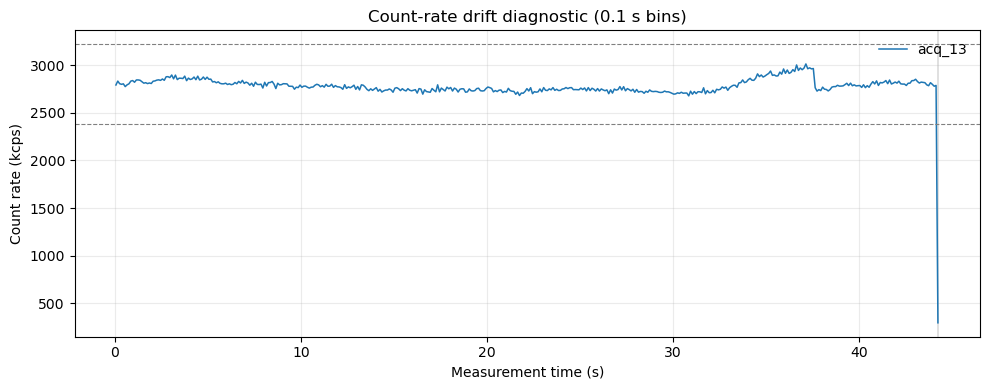

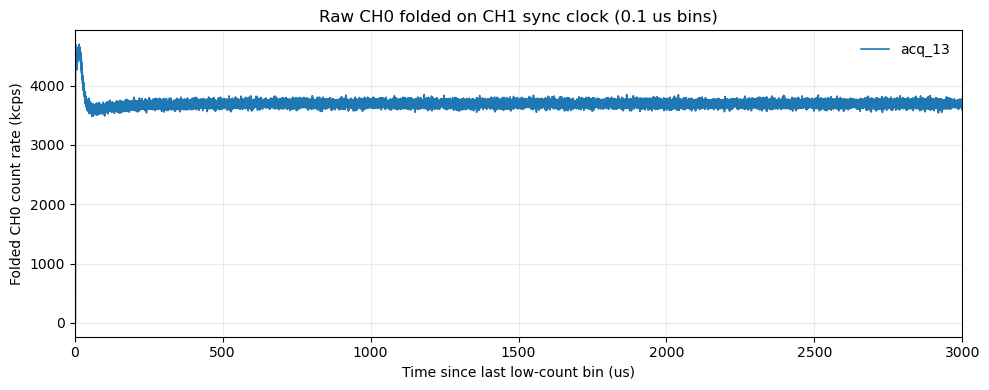

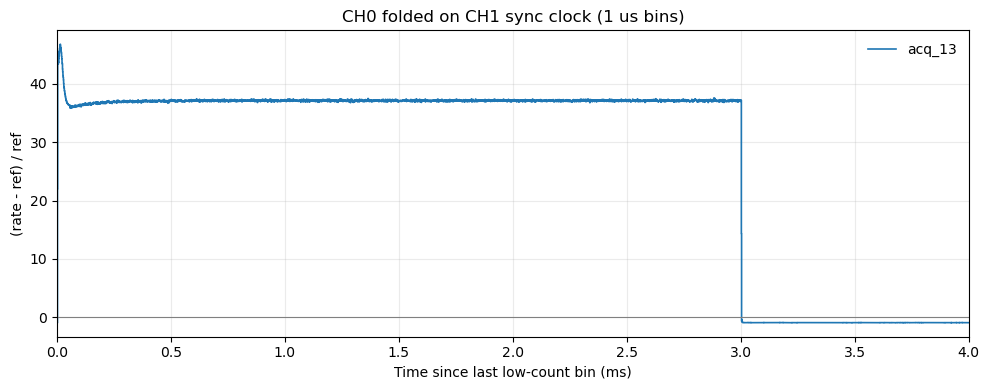

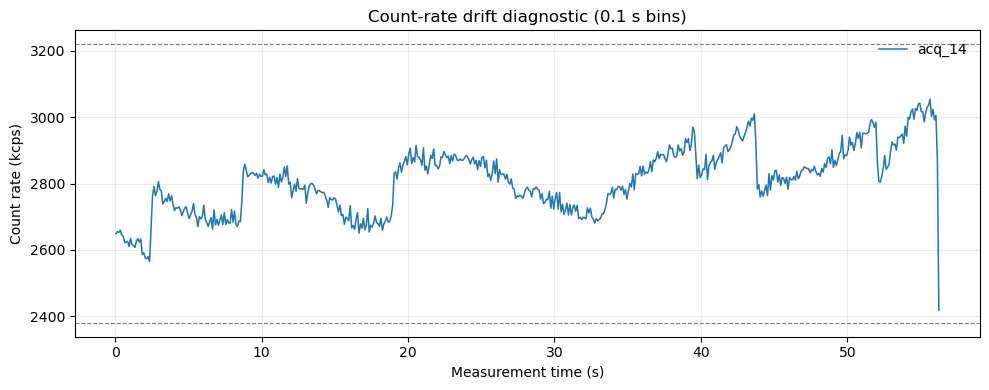

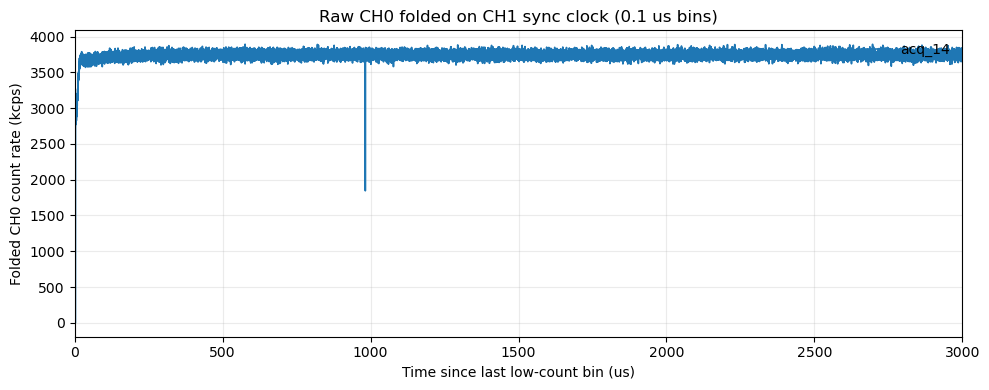

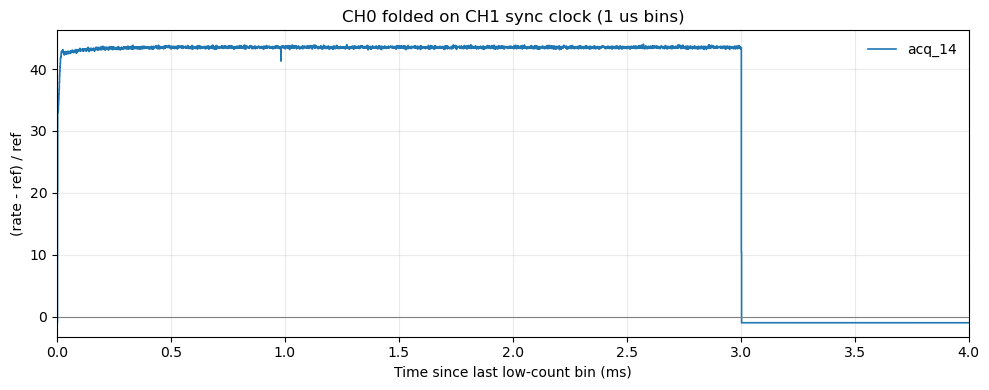

In [ ]:


DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260613_test")

acq_time_s = 60
for i in range(13,40):
    succesful = False
    tstart = time.time()

    while not succesful:
        try: 
            results = analyze_new_timetrace(
                [i],
                sync_tick_stride=1,
                desired_count_rate_kcps=2800,
                tolerance=0.15,
                data_root=DATA_ROOT,
                t0_method="threshold",
                normalized_lims=None,#[0,1.95],
                ref_range=[3,3.1],
                unit='ms'
            )
            succesful = True
            
        except Exception as e:
            print(e)
            print("Analysis of acquisition ",i, " failed at the moment")
            time.sleep(acq_time_s)
    tend = time.time()
    time.sleep(max(0.1,acq_time_s-(tend-tstart)))


# Optional: Clean up the record from periods where the count rate is low

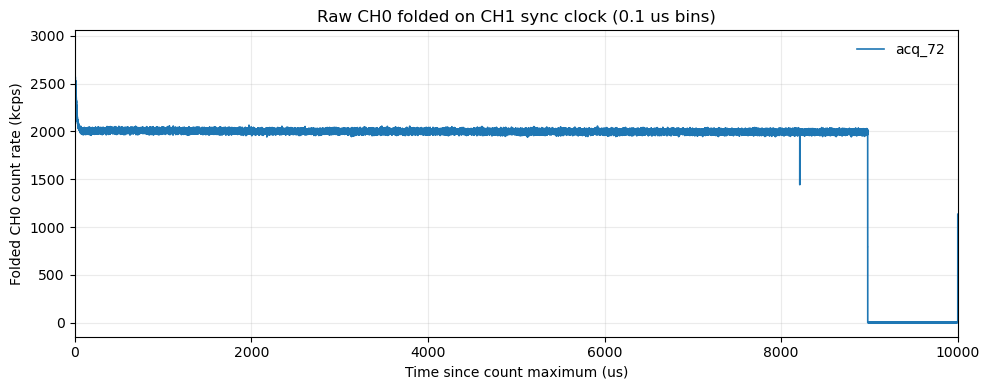

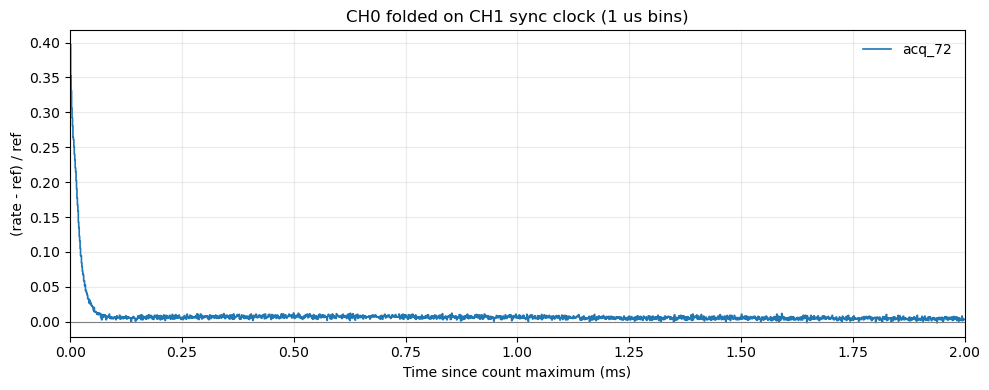

In [ ]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260607_vmu_scan4")

low_event_exclude_ranges_s = {
    72: [[21.2, 331.5]],
}

low_event_reanalysis = {}

for acq_id, exclude_ranges in low_event_exclude_ranges_s.items():
    fig_raw, ax_raw, raw_traces = plot_raw_sync_traces(
        [acq_id],
        sync_tick_stride=10,
        bin_us=0.1,
        lims=[0, 10e3],
        measurement_exclude_ranges_s=exclude_ranges,
        force_recompute=True,
        data_root=DATA_ROOT,
        fig_name=f"acq_{acq_id}_raw_sync_low_event_excluded_gt25s.png",
    )

    fig_norm, ax_norm, norm_traces = plot_normalized_sync_traces(
        [acq_id],
        sync_tick_stride=10,
        bin_us=1,
        lims=[0, 2],
        ref_range=[8.5, 8.8],
        unit="ms",
        measurement_exclude_ranges_s=exclude_ranges,
        force_recompute=False,
        data_root=DATA_ROOT,
        fig_name=f"acq_{acq_id}_normalized_sync_low_event_excluded_gt25s.png",
    )

    low_event_reanalysis[acq_id] = {
        "exclude_ranges_s": exclude_ranges,
        "raw": raw_traces,
        "normalized": norm_traces,
    }